In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dictys.plot.static import compute_spec
from dictys.plot import dotplot
from dictys.net import network
import pandas as pd
import seaborn as sns

#Load networks
d0=network.from_file("/home/jinggu/cluster/projects/u19_multiomics/analyses/remove_dup/dictys/static.h5")
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state = compute_spec(d0,nmax=20,vmin=0,ncut=0.4,min_entropy=0.8,sparsity=0.02) #select_state = select_state)

#Rename cell subsets
d_names = {}
for i in deg.columns:
    d_names[i] = i.split("Subset")[1]
    if d_names[i].startswith("L_"):
        d_names[i] = i.split("SubsetL_")[1]
d0.rename('s', d_names)

#Regulation markers based on TF regulatory activity (by target count) and its specificity
#Color map of specificity
cmap='Blues'#'spring_r'
#Node sizes to draw legend in dot plot
node_size_deg=[20,100,200,500]
#Transformation from target count to node size
node_size_map_deg=lambda x:x*(x<=10)+(10+(x-10)*500/10/490)*(x>10)

In [3]:
from functools import partial
import numpy as np
from dictys.net.layout import _fruchterman_reingold
from dictys.net import stat
from dictys.plot import panel

def retrieve_edges_GRNs(state, sparsity_value=0.02):
    pts=np.array([d0.sdict[state]])
    stat1_net=stat.net(d0)
    stat1_netbin=stat.fbinarize(stat1_net,sparsity=sparsity_value)
    #Subnetwork
    stat1_subnet,stat1_subnetbin=stat1_net,stat1_netbin
    transformation=lambda x:x
    stat1_subnet_trunc=stat.function(lambda *x:transformation(x[0]*x[1]),[stat1_subnet,stat1_subnetbin],names=stat1_subnet.names)
    edges=stat1_subnet_trunc.compute(pts)[:,:,0]
    t1=np.nonzero(edges)
    edges=pd.DataFrame([stat1_subnet_trunc.names[0][t1[0]],stat1_subnet_trunc.names[1][t1[1]],edges[t1[0],t1[1]]],index=['Regulator','Target','Strength']).T
    return(edges)


ct_order=["Naive_B", "Memory_B", "NK", "CD8_T", "CD4_T", "Treg"]
d_edges={}
for c in ct_order:
    d_edges[c]=retrieve_edges_GRNs(c, sparsity_value=0.015)

d_targets={}
d_regs={}
for c in d_edges.keys():
    target_sets=d_edges[c].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    d_targets[c]=np.array([len(i) for i in target_sets])
    reg_sets=d_edges[c].groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
    d_regs[c]=np.array([len(i) for i in reg_sets])

In [4]:
asthma_genes = ["IRF1","GATA3","SMAD3","TBX21","BACH2","CEBPA","STAT6"]

In [4]:
pd.DataFrame(deg).to_csv("sparsity0.02/heatmap_deg.txt", index = True)
pd.DataFrame(deg_spec).to_csv("sparsity0.02/heatmap_deg_spec.txt", index = True)
pd.DataFrame(cpm).to_csv("sparsity0.02/heatmap_cpm.txt", index = True)
pd.DataFrame(cpm_spec).to_csv("sparsity0.02/heatmap_cpm_spec.txt", index = True)

NameError: name 'deg' is not defined

In [ ]:
pd.DataFrame(
    {"regmarker_state":regmarker_state,
     "regmarker": regmarker}).to_csv("sparsity0.02/heatmap_regmarkerDF.txt")
    

In [5]:
plt.rcParams.update({'font.size': 11,
                     'figure.figsize': (10, 14),
                     'figure.dpi': 180})

In [13]:
regmarker = np.append(np.append(regmarker[0:16],["SMAD1","LEF1"]), regmarker[17:20])

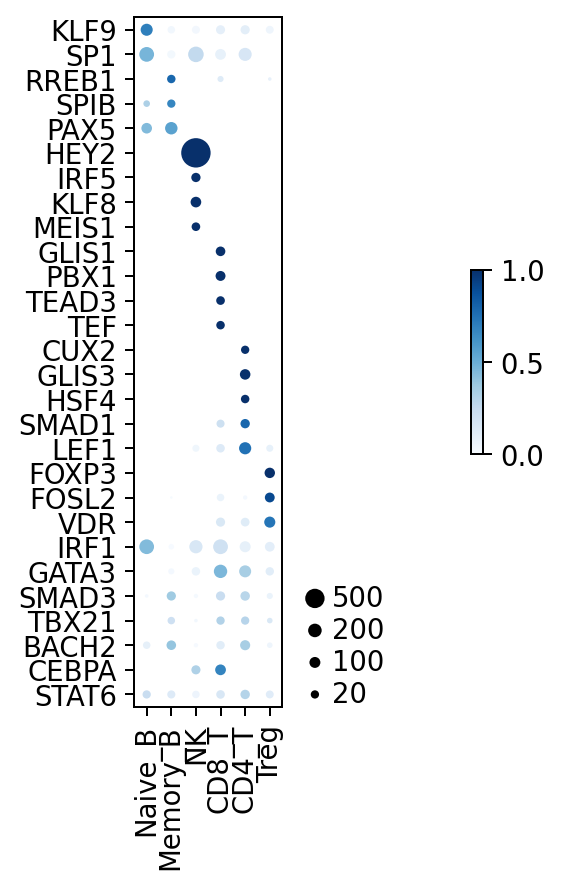

In [13]:
#Find marker genes based on regulatory activity specificity
select_state = 'Naive_B,Memory_B,NK,CD8_T,CD4_T,Treg'.split(',')
#Arguments control how many top markers to show and the cutoffs for target count, its specificity at the most abundant cell subset, and its entropy over all cell subsets
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state = compute_spec(d0,nmax=3,sparsity=0.015, min_entropy=0.8, select_state = select_state)
#Draw dot plot with regulatory activity and its specificity
# for visualization
regmarker = np.append(np.append(regmarker[0:16],["SMAD1","LEF1"]), regmarker[17:20])
#regmarker = np.append(regmarker[0:16], regmarker[24:len(regmarker)])
fig,ax=dotplot(deg.loc[np.append(regmarker, asthma_genes)].iloc[::-1],deg_spec.loc[np.append(regmarker, asthma_genes)].iloc[::-1],size_transform=node_size_map_deg,sizes=np.array(node_size_deg),cmap=cmap)


In [14]:
fig.set_size_inches(3, 5, forward=True)
fig.savefig("Heatmap_target_counts.pdf", format="pdf", bbox_inches="tight")

In [38]:
regmarker

array(['KLF9', 'SP1', 'RREB1', 'SPIB', 'PAX5', 'HEY2', 'IRF5', 'KLF8',
       'MEIS1', 'GLIS1', 'PBX1', 'TEAD3', 'TEF', 'CUX2', 'GLIS3', 'HSF4',
       'SMAD1', 'LEF1', 'FOXP3', 'FOSL2', 'VDR'], dtype='<U14')

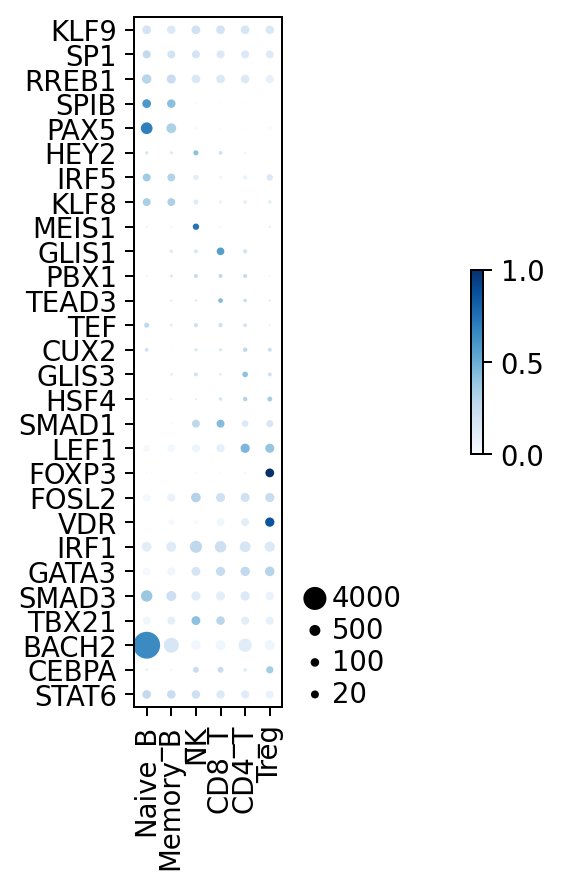

In [8]:
#Redraw of expression marker plot
deg,deg_spec,cpm,cpm_spec,expmarker,expmarker_state=compute_spec(d0,base='cpm',nmax=7,sparsity=0.015, min_entropy=0.8, select_state = select_state)
#select_state=selected)
# cpm=cpm.loc[:, new_cols]
# cpm_spec=cpm_spec.loc[:, new_cols]
# cpm=deg.loc[:, ct_order]
# cpm.columns = [i.split("lungs_")[1] for i in ct_order]
# cpm_spec=cpm_spec.loc[:, ct_order]
# cpm_spec.columns = [i.split("lungs_")[1] for i in ct_order]

#Node sizes to draw legend in dot plot for expression (CPM)
node_size_cpm=[20,100,500,4000]
#Transformation from target count to node size for regulation
node_size_map_cpm=lambda x:x*(x<=10)+(10+(x-10)*1500/20/3990)*(x>10)
#node_size_map_cpm=lambda x:x*(x<=500)+(10+(x-10)*1000/20/990)*(x>500)

#Draw dot plot of expression level and expression specificity with top regulation marker genes
fig2,ax2=dotplot(cpm.loc[np.append(regmarker, asthma_genes)].iloc[::-1], 
                 cpm_spec.loc[np.append(regmarker, asthma_genes)].iloc[::-1],vrange=[0, 1], size_transform=node_size_map_cpm, sizes=np.array(node_size_cpm),cmap=cmap)
#ax2.tick_params(top=True,labeltop=True)

In [11]:
fig2.set_size_inches(3, 5, forward=True)
fig2.savefig("Heatmap_RNA_counts.pdf", format="pdf", bbox_inches="tight")

In [96]:
plt.rcParams.update({'font.size': 15,
                     'figure.figsize':(4,4),
                     'figure.dpi': 150})

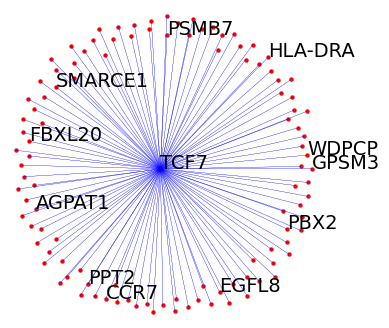

In [10]:
from dictys.plot.static import fig_subnet
fig=plt.figure(figsize=(4,4))
ax=fig.add_subplot(111)
tf = 'STAT2'
targets = "AGPAT1,CCR7,EGFL8,FBXL20,GPSM3,HLA-DRA,PBX2,PPT2,PSMB7,SMARCE1,WDPCP".split(",")
nodes,edges=fig_subnet(d0,ax,'CD4_T',regulators=[tf],
                            sparsity = 0.02,
                            annotate= targets + [tf],
                            ka_node = {'s':10, 'color':'red'},
                            ka_edge = {'lw': 0.1, 'color': 'blue'})

In [29]:
ct_order = ['Naive_B', 'Memory_B', 'NK', 'CD8_T','CD4_T', 'Treg']

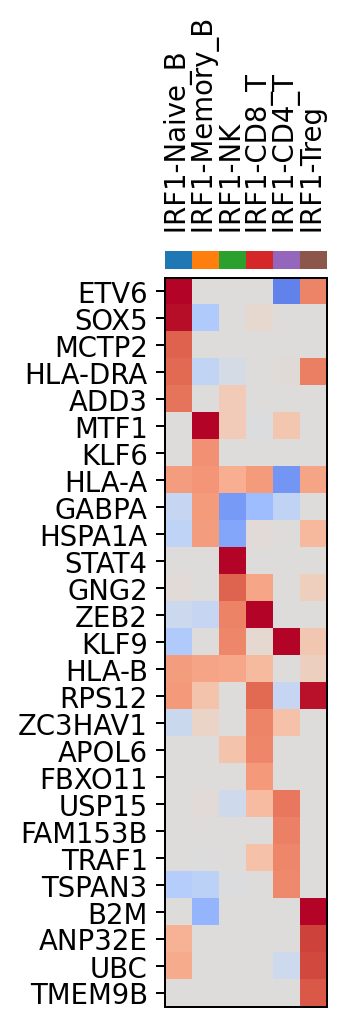

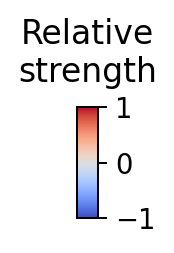

In [37]:
tf=['IRF1']
#tf= ['PPARG', 'PBX2', 'NR1D1']
tf_sets = []
for i in tf:
    for j in ct_order:
        if deg[deg.index==i][j].any(): #check if any or more element are non-zero
            tf_sets.append((i, j))

from dictys.plot.static import fig_heatmap_top
#Number of top targets for each TF
ntop=5
#Searching for top activated target genes only
direction=1

fig,fig_colorbar,net=fig_heatmap_top(d0,tf_sets,ntop=ntop,
                                     direction=direction,aspect=1,gann='all', )

In [38]:
net.to_csv("../../data/plots/IRF1_grn_top5.csv")

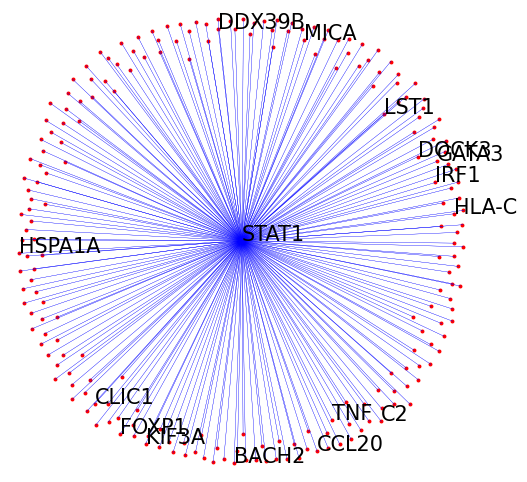

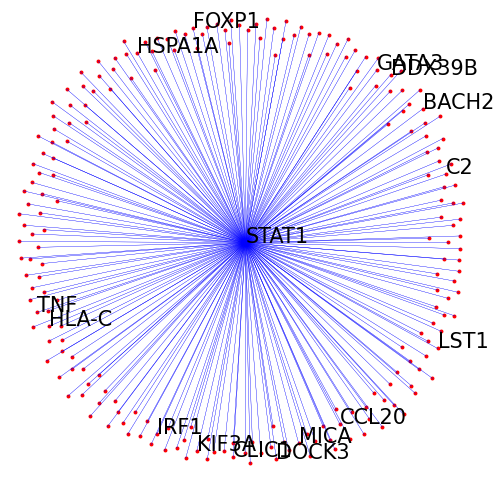

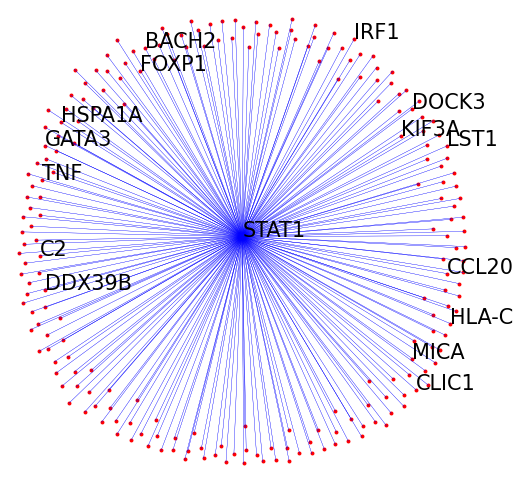

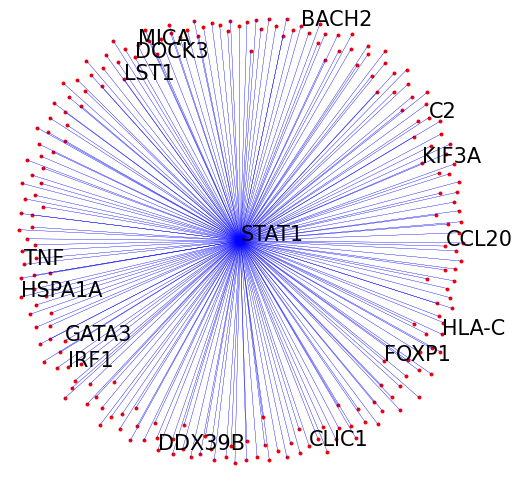

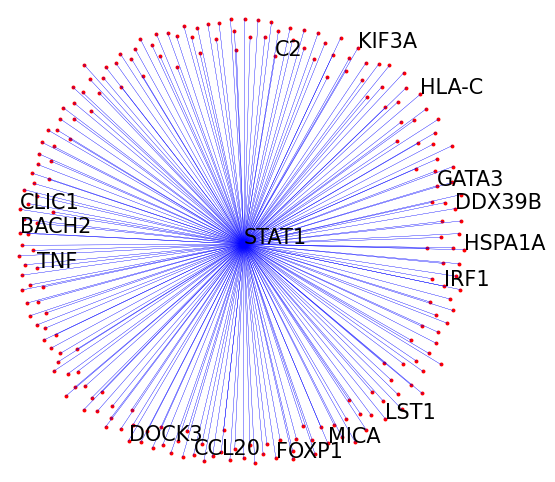

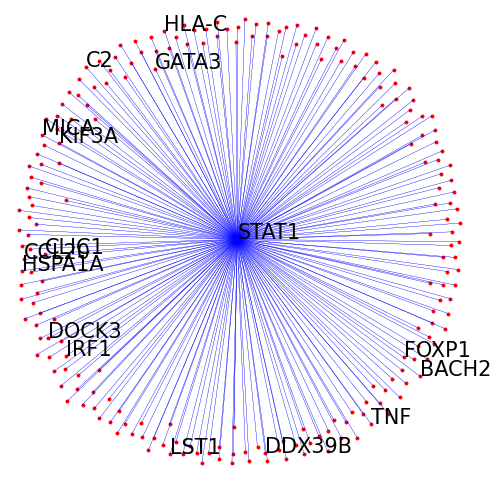

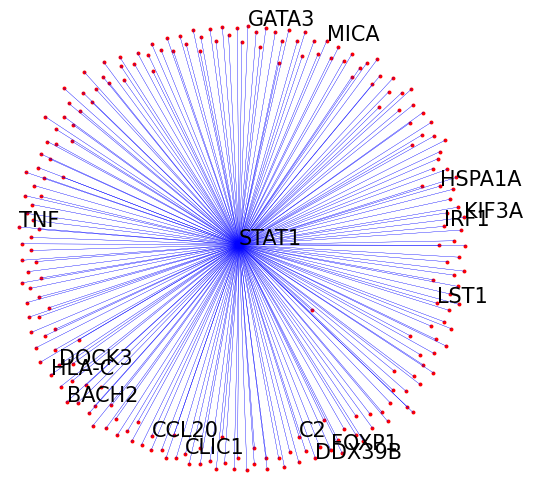

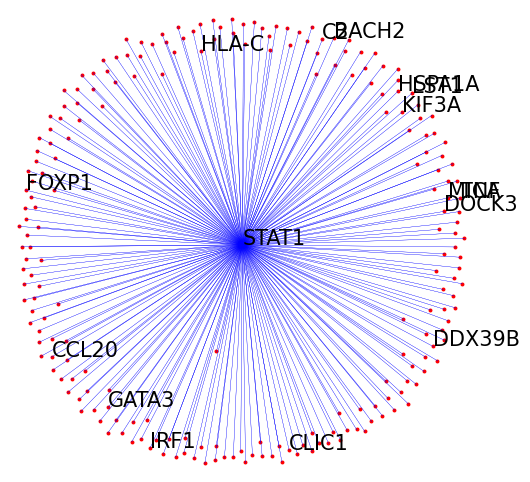

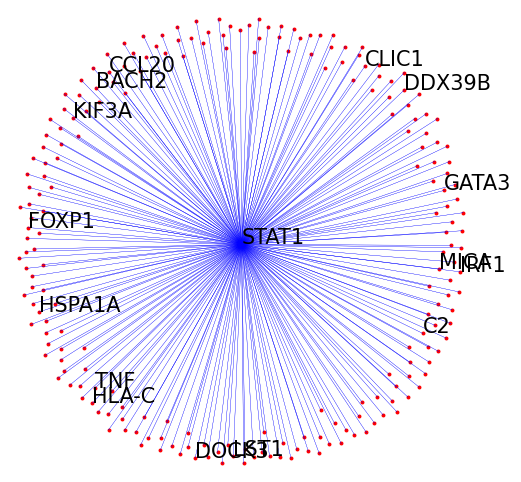

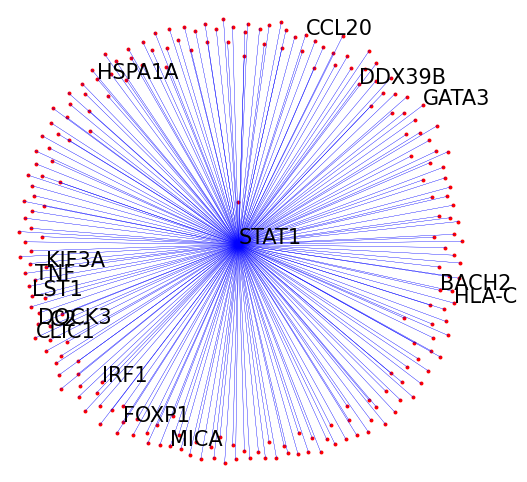

In [95]:
for i in list(range(0, 10)):
    fig=plt.figure(figsize=(6,6))
    ax=fig.add_subplot(111)
    highlighted = 'ABHD16A,BACH2,BAG6,C2,CCL20,CLIC1,DDX39B,DOCK3,FOXP1,GATA3,HLA-B,HLA-C,HSPA1A,IRF1,KIF3A,LST1,MED1,MICA,SKIV2L,TBL1XR1,TNF'.split(',')
    tf = 'STAT1'
    nodes,edges=fig_subnet(d0,ax,'L_Th17',regulators=[tf],
                           sparsity = 0.009,
                           annotate=highlighted + [tf],
                           ka_node = {'s':8, 'color':'red'},
                           ka_edge = {'lw': 0.1, 'color': 'blue'})

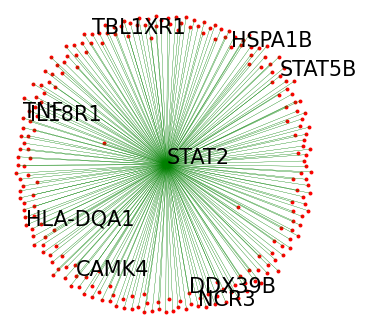

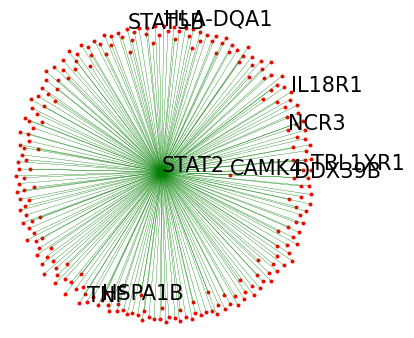

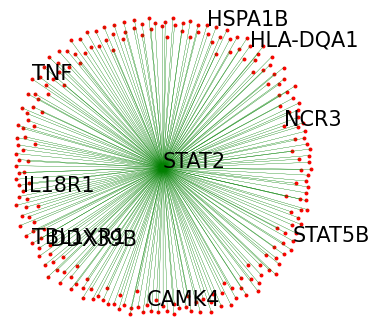

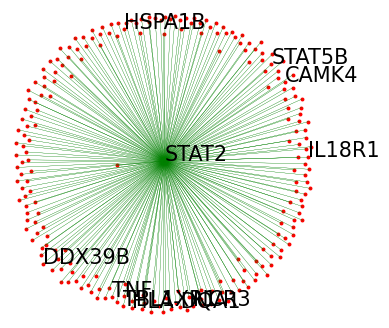

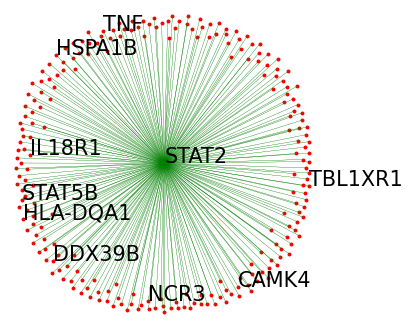

In [105]:
for i in list(range(0, 5)):
    fig=plt.figure(figsize=(4,4))
    ax=fig.add_subplot(111)
    highlighted = 'CAMK4,DDX39B,HLA-DQA1,HSPA1B,IL18R1,NCR3,STAT5B,TBL1XR1,TNF'.split(',')
    tf = 'STAT2'
    nodes,edges=fig_subnet(d0,ax,'L_CD4_T',regulators=[tf],
                           sparsity = 0.015,
                           annotate=highlighted + [tf],
                           ka_node = {'s':8, 'color':'red'},
                           ka_edge = {'lw': 0.1, 'color': 'green'})

In [7]:
ct_order = ['Naive_B', 'Memory_B', 'CD4_T', 'CD8_T', 'Th17', 'Treg']

In [9]:
tf = ["BACH2","IRF1","GATA3","SMAD3","TBX21","CEBPA","STAT6"]
tf = ["GATA3"]
tf_sets = []
for i in tf:
    for j in ct_order[1:]:
        if deg[deg.index==i][j].any(): #check if any or more element are non-zero
            tf_sets.append((i, j))

KeyError: 'Memory_B'

In [103]:
tf_sets

[('GATA3', 'Memory_B'),
 ('GATA3', 'CD4_T'),
 ('GATA3', 'CD8_T'),
 ('GATA3', 'Th17'),
 ('GATA3', 'Treg')]

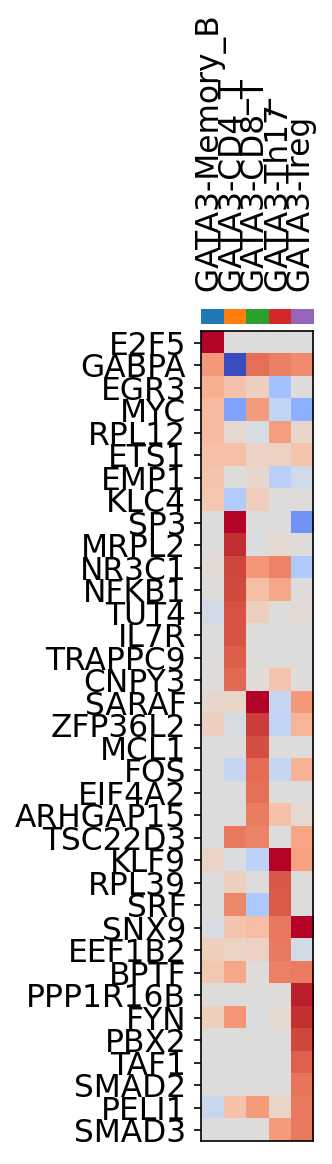

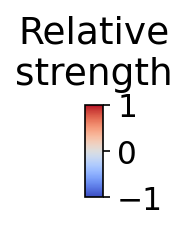

In [104]:
from dictys.plot.static import fig_heatmap_top
#Number of top targets for each TF
ntop=8
#Searching for top activated target genes only
direction=1

fig,fig_colorbar,net=fig_heatmap_top(d0,tf_sets,ntop=ntop,
                                     direction=direction,aspect=1,gann='all')

In [80]:
net.head()

,GATA3-Memory_B,GATA3-CD4_T,GATA3-CD8_T,GATA3-Th17,GATA3-Treg
E2F5,1.000000,0.000000,0.000000,0.000000,0.000000
GABPA,0.505738,-0.999466,0.692045,0.620081,0.566112
EGR3,0.377752,0.264881,0.156049,-0.367460,0.000000
MYC,0.319854,-0.577703,0.487794,-0.193360,-0.493455
RPL12,0.315612,0.069042,-0.045681,0.482874,0.090536


In [105]:
pd.DataFrame(net).to_csv("./GATA3_top8_targets_across_cell_types.csv")

In [29]:
edges

,Regulator,Target,Strength
0,TBX21,AIFM1,-0.197425
1,TBX21,ASB3,-0.216051
2,TBX21,BAK1,-0.178323
3,TBX21,BCCIP,-0.297947
4,TBX21,CBWD1,-0.181787
5,TBX21,CCDC62,0.447932
6,TBX21,CD200R1,0.539412
7,TBX21,CERS6,-0.193879
8,TBX21,CHRNE,-0.192814
9,TBX21,FAM135A,-0.197821
